# 측정 I-V 역산 — 검증과 사용법

`inverse.py`로 측정 I-V에서 필라멘트 지름·개수, 갭, 산화막 비저항, 속도 파라미터를 역산한다. 여기서는 **정답을 아는 가상 측정**(2차원 모델로 만든 I-V에 1% 잡음)을 역산해 값이 되돌아오는지 확인한다. 실제 측정에 쓰는 법은 마지막 절에 있다.

방법 (Russo et al., IEEE TED 56(2) 186–192, 2009 = [C]):

| 단계 | 측정 | 식 | 얻는 값 |
|---|---|---|---|
| 1 | 포밍 전 I-V | ρ_ox = R·A_cell/L0 (A44) | 산화막 비저항 |
| 2 | RESET I-V | [C] 식 (5): R = R0[1 + γα(T_max − T0)], γ = 2/3 | 필라멘트 최고 온도 T(V) |
| | | [C] 식 (6): T_crit = T0 + P_reset·Rth | 임계 온도, 등가 열저항 |
| | 램프 속도 2가지 이상 | [C] 식 (10),(11) Kissinger (참고) / 2차원 모델로 V_reset 맞춤 (A47) | 열 용해 활성화 에너지 E_d |
| 3 | R0, Rth | N개 병렬이면 Rth/R0는 N과 무관 → 2차원 모델로 지름, R0로 개수 (A43) | 필라멘트 지름·개수 |
| 4 | SET I-V의 저전계 저항 (HRS) | 2차원 모델 (A45) | 유효 갭 |
| 5 | V_reset, V_set | 같은 램프 속도·전류 제한으로 과도 계산 | v_D0, E_a |

저항 온도 계수 α는 온도별 LRS 저항 측정([C] 식 (1))에서 얻어야 한다. 여기서는 가상 소자의 값을 안다고 둔다.

In [1]:
import time
from dataclasses import replace
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

import rram_model as rm
import inverse as inv

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
rng = np.random.default_rng(1)
EX = Path("examples")
EX.mkdir(exist_ok=True)

# 역산할 때 아는 것: 소자 구조(두께, 셀 면적, TiN 전극)와 물성
base = replace(rm.DEFAULT, **rm.TIN_ELECTRODE, A_cell=1e-12)
# 가상 소자의 정답 (역산할 때는 모름): 지름 40 nm 필라멘트 2개, v_D0 100 m/s, E_a 0.75 eV
truth = replace(base, n_f=2e12, phi0=40e-9, vD0=100.0, Ea=0.75 * rm.EV)
print("정답 N =", truth.N)

정답 N = 2


## 1. 가상 측정 만들기

포밍 전(산화막만), RESET 3번(램프 0.1 / 1 / 10 V/s, RESET 직후 측정 중단), SET 1번(전류 제한 1 mA, 1 V/s). 0.02 V 계단으로 읽고 1% 잡음을 넣는다.

185 s, 저장: examples/synthetic_measurement.csv
정답 HRS: 가장 가는 곳 반경 0.94 nm, 저전계 저항 1.177e+04 Ω


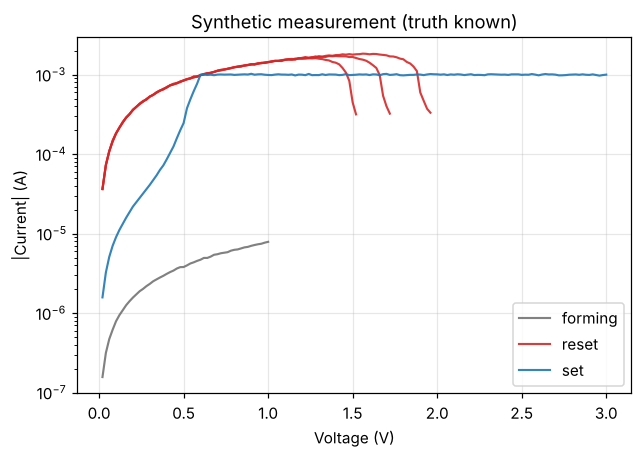

In [2]:
STEP = 0.02

def sample(r, step=STEP):
	grid = np.arange(step, r.v_app.max() + 1e-9, step)
	ii = np.interp(grid, r.v_app, r.i)
	return grid, ii * (1 + 0.01 * rng.standard_normal(len(grid)))

def cut_after_reset(v, i):
	# RESET 뒤 전류가 최대값의 1/5 아래로 떨어진 점까지만 남긴다 (측정 중단 흉내)
	k = int(np.argmax(i))
	below = np.where(i[k:] < 0.2 * i[k])[0]
	stop = k + int(below[0]) if below.size else len(v) - 1
	return v[:stop + 1], i[:stop + 1]

sweeps = []
R_pristine = truth.RL + truth.rho_ox * truth.L0 / truth.A_cell
vf = np.arange(STEP, 1.0 + 1e-9, STEP)
sweeps.append(inv.Sweep(0, "forming", vf, vf / R_pristine * (1 + 0.01 * rng.standard_normal(len(vf)))))
rb_lrs = inv.uniform_cf(truth.phi0, truth)
raw = {}
t0 = time.time()
for k, rate in enumerate([0.1, 1.0, 10.0], start=1):
	r = rm.simulate(rm.ramp_waveform("reset", 2.6, rate), rb_lrs, truth)
	raw[rate] = r
	v, i = cut_after_reset(*sample(r))
	sweeps.append(inv.Sweep(k, "reset", v, i, rate))
rb_hrs = raw[1.0].rb_end
r_set = rm.simulate(rm.ramp_waveform("set", 3.0, 1.0), rb_hrs, truth, i_cc=1e-3)
v, i = sample(r_set)
sweeps.append(inv.Sweep(4, "set", v, i, 1.0, 1e-3))
inv.save_sweeps(EX / "synthetic_measurement.csv", sweeps)
print(f"{time.time()-t0:.0f} s, 저장: {EX / 'synthetic_measurement.csv'}")
print(f"정답 HRS: 가장 가는 곳 반경 {rb_hrs.min()*1e9:.2f} nm, 저전계 저항 {inv.device_resistance(rb_hrs, truth.N, truth):.4g} Ω")

fig, ax = plt.subplots(figsize=(6.5, 4.2))
colors = {"forming": "0.45", "reset": "C3", "set": "C0"}
for s in sweeps:
	ax.semilogy(s.v, np.abs(s.i), color=colors[s.op], lw=1.4, alpha=0.9, label=s.op if s.op not in ax.get_legend_handles_labels()[1] else None)
ax.set(xlabel="Voltage (V)", ylabel="|Current| (A)", title="Synthetic measurement (truth known)")
ax.legend()

## 2. Russo 추출: 필라멘트 온도, 임계 온도, 열저항, Kissinger

  0.1 V/s: R0 536.6 Ω, V_reset 1.280 V, I_reset 1.612 mA, T_crit 691 K, Rth 1.63e+05 K/W (식 6: 1.89e+05), σ/κ 2.43e+03
    1 V/s: R0 536.8 Ω, V_reset 1.400 V, I_reset 1.717 mA, T_crit 725 K, Rth 1.63e+05 K/W (식 6: 1.77e+05), σ/κ 2.43e+03
   10 V/s: R0 536.4 Ω, V_reset 1.560 V, I_reset 1.838 mA, T_crit 781 K, Rth 1.6e+05 K/W (식 6: 1.68e+05), σ/κ 2.39e+03
정답   0.1 V/s: 모델 최고 온도 579 K (V 1.250)
정답     1 V/s: 모델 최고 온도 634 K (V 1.400)
정답    10 V/s: 모델 최고 온도 703 K (V 1.580)


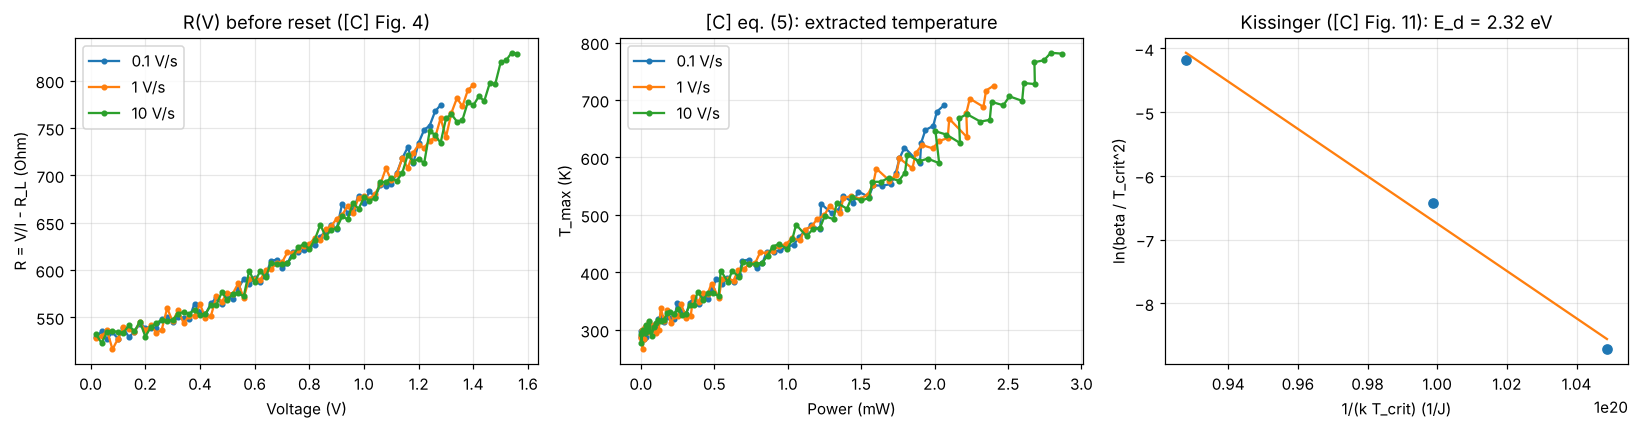

In [3]:
loaded = inv.load_sweeps(EX / "synthetic_measurement.csv")
alpha = truth.alpha_T	# 실제 소자는 온도별 LRS 저항 측정에서
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
pts = []
for s in loaded:
	if s.op != "reset":
		continue
	f = inv.reset_features(s.v, s.i, base.RL)
	rr = inv.russo_extraction(f, alpha, base.T0)
	pts.append((s.rate, f.v_reset, rr.T_crit, rr.Rth_fit, f.R0))
	ax[0].plot(f.v, f.R, ".-", label=f"{s.rate:g} V/s")
	ax[1].plot(f.P * 1e3, rr.T, ".-", label=f"{s.rate:g} V/s")
	print(f"{s.rate:5g} V/s: R0 {f.R0:.4g} Ω, V_reset {f.v_reset:.3f} V, I_reset {f.i_reset*1e3:.3f} mA, T_crit {rr.T_crit:.0f} K, Rth {rr.Rth_fit:.3g} K/W (식 6: {rr.Rth_reset:.3g}), σ/κ {rr.sigma_kappa:.3g}")
ax[0].set(xlabel="Voltage (V)", ylabel="R = V/I - R_L (Ohm)", title="R(V) before reset ([C] Fig. 4)")
ax[1].set(xlabel="Power (mW)", ylabel="T_max (K)", title="[C] eq. (5): extracted temperature")
for a in ax[:2]:
	a.legend()
Ed, icpt, x, y = inv.kissinger(pts)
ax[2].plot(x, y, "o")
ax[2].plot(x, icpt - Ed * x, "-")
ax[2].set(xlabel="1/(k T_crit) (1/J)", ylabel="ln(beta / T_crit^2)", title=f"Kissinger ([C] Fig. 11): E_d = {Ed/rm.EV:.2f} eV")
plt.tight_layout()
# 정답 비교: 모델 안의 실제 최고 온도 (RESET 점)
for rate, r in raw.items():
	k = int(np.argmax(r.i))
	print(f"정답 {rate:5g} V/s: 모델 최고 온도 {r.T[k]:.0f} K (V {r.v_app[k]:.3f})")

**주의:** [C] 식 (5)의 γ = 2/3은 필라멘트를 따라 온도가 포물선이라는 가정이다. TiN 전극처럼 전극으로 열이 덜 빠지면 온도 분포가 평평해져 γ가 커지고(이 소자는 약 0.81), 식 (5)는 온도를 수십~100 K 높게 잡는다. Kissinger 기울기는 온도 오차에 매우 민감해서, 여기서 뽑은 E_d는 정답(1.2 eV)과 크게 다르다. 모델 안의 실제 온도를 넣으면 1.24 eV로 맞는다. 그래서 E_d와 v_D0는 5절처럼 **2차원 모델로 램프 속도별 V_reset을 직접 맞추고**, Kissinger 값은 참고로만 쓴다 (A47).

## 3. 필라멘트 지름과 개수

같은 필라멘트 N개가 병렬이면 R0 = R_fil/N, Rth = Rth_fil/N이라 **Rth/R0는 N과 무관**하다. 2차원 모델로 지름별 Rth/R0를 같은 추출법으로 계산해, 측정값과 만나는 지름을 찾는다. 이것은 [C] 식 (7)의 σ/κ 분석과 같은 원리다.

[1] 포밍 전 저항 1.28e+05 Ω → 산화막 비저항 0.798 Ω·m
[2] RESET 3개: R0 536.6 Ω, V_reset 1.4 V, T_crit 725 K, Rth 1.63e+05 K/W
    참고: Kissinger E_d = 2.32 eV ([C] 식 (5) 온도 사용, 온도 오차에 매우 민감해 모델에 넣지 않음, A47)


[3] 필라멘트 지름 38.8 nm (Rth/R0 ±20% → 34.2–43.1 nm), 개수 2.09
[4] HRS 9980 Ω → 완전히 끊긴 갭으로는 저항이 너무 커서 설명 안 됨; 길이 8 nm 잘록 구간이면 반경 1.00 nm
10 s


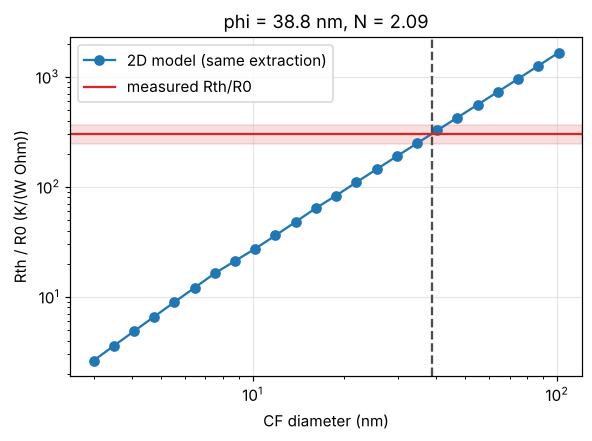

In [4]:
t0 = time.time()
res = inv.invert(loaded, base, alpha=alpha, kinetics=False)
print(f"{time.time()-t0:.0f} s")
c = res.lrs.curve
R0m = np.median([f.R0 for _, f, _ in res.reset])
Rthm = np.median([rr.Rth_fit for _, _, rr in res.reset])
fig, ax = plt.subplots(figsize=(6, 4))
ax.loglog(c["phi"] * 1e9, c["ratio"], "o-", label="2D model (same extraction)")
ax.axhline(Rthm / R0m, color="C3", label="measured Rth/R0")
ax.axhspan(0.8 * Rthm / R0m, 1.2 * Rthm / R0m, color="C3", alpha=0.15)
ax.axvline(res.lrs.phi * 1e9, color="0.3", ls="--")
ax.set(xlabel="CF diameter (nm)", ylabel="Rth / R0 (K/(W Ohm))", title=f"phi = {res.lrs.phi*1e9:.1f} nm, N = {res.lrs.N:.2f}")
ax.legend()

## 4. 갭 (HRS)

HRS 저항 하나로는 끊긴 곳의 반경과 길이를 함께 정할 수 없다. 두 가지로 푼다: (1) 반경 0인 갭의 길이, (2) 길이 8 nm 잘록 구간의 반경 (A45).

끊긴 갭 길이 nan nm, 또는 길이 8 nm 잘록 구간 반경 1.00 nm
정답 HRS: 가장 가는 곳 0.94 nm, 가운데 8 nm 평균 반경 0.94 nm


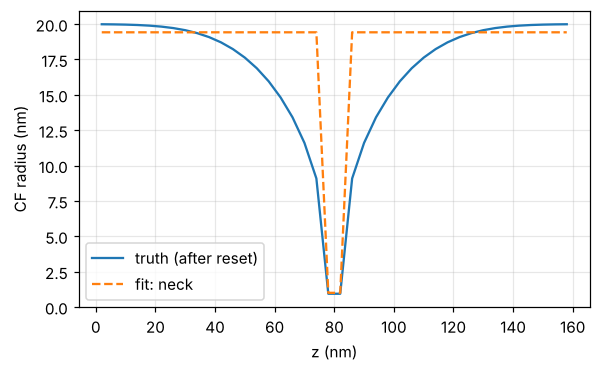

In [5]:
print(f"끊긴 갭 길이 {res.gap.gap*1e9:.2f} nm, 또는 길이 {res.gap.neck_len*1e9:.0f} nm 잘록 구간 반경 {res.gap.r_neck*1e9:.2f} nm")
g = rm.make_grid(truth)
mid = np.abs(g.zc - truth.L0 / 2) <= 4e-9
print(f"정답 HRS: 가장 가는 곳 {rb_hrs.min()*1e9:.2f} nm, 가운데 8 nm 평균 반경 {rb_hrs[mid].mean()*1e9:.2f} nm")
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(g.zc * 1e9, rb_hrs * 1e9, label="truth (after reset)")
ax.plot(g.zc * 1e9, inv.gap_profile(res.lrs.phi, res.gap.neck_len, base, r_neck=res.gap.r_neck) * 1e9, "--", label="fit: neck")
if np.isfinite(res.gap.gap):
	ax.plot(g.zc * 1e9, inv.gap_profile(res.lrs.phi, res.gap.gap, base) * 1e9, ":", label="fit: gap")
ax.set(xlabel="z (nm)", ylabel="CF radius (nm)")
ax.legend()

## 5. 속도 파라미터 (과도 계산)

램프 속도별 RESET 전압이 맞도록 E_d와 v_D0를 함께 찾는다: E_d를 정하면 가운데 램프 속도의 V_reset으로 v_D0가 정해지고, 가장 느린·빠른 램프의 V_reset 차이가 측정과 같아지도록 E_d를 찾는다. 같은 전류 제한에서 SET 전압이 맞도록 E_a를 찾는다. 과도 계산을 수십 번 하므로 수십 분 걸린다.

In [6]:
t0 = time.time()
res_k = inv.invert(loaded, base, alpha=alpha, kinetics=True)
print(f"{time.time()-t0:.0f} s")

[1] 포밍 전 저항 1.28e+05 Ω → 산화막 비저항 0.798 Ω·m
[2] RESET 3개: R0 536.6 Ω, V_reset 1.4 V, T_crit 725 K, Rth 1.63e+05 K/W
    참고: Kissinger E_d = 2.32 eV ([C] 식 (5) 온도 사용, 온도 오차에 매우 민감해 모델에 넣지 않음, A47)


[3] 필라멘트 지름 38.8 nm (Rth/R0 ±20% → 34.2–43.1 nm), 개수 2.09
[4] HRS 9980 Ω → 완전히 끊긴 갭으로는 저항이 너무 커서 설명 안 됨; 길이 8 nm 잘록 구간이면 반경 1.00 nm


    E_d 0.800 eV → v_D0 0.0631 m/s, V_reset 차이 0.470 V (측정 0.280 V)


    E_d 2.000 eV → v_D0 1.21e+09 m/s, V_reset 차이 0.200 V (측정 0.280 V)


    E_d 1.644 eV → v_D0 1.11e+06 m/s, V_reset 차이 0.240 V (측정 0.280 V)


    E_d 1.351 eV → v_D0 3.43e+03 m/s, V_reset 차이 0.290 V (측정 0.280 V)


    E_d 1.409 eV → v_D0 1.09e+04 m/s, V_reset 차이 0.280 V (측정 0.280 V)


    E_d 1.399 eV → v_D0 8.94e+03 m/s, V_reset 차이 0.280 V (측정 0.280 V)


    E_d 1.375 eV → v_D0 5.56e+03 m/s, V_reset 차이 0.290 V (측정 0.280 V)


    E_d 1.389 eV → v_D0 7.34e+03 m/s, V_reset 차이 0.290 V (측정 0.280 V)
[5] RESET 속도: E_d 1.399 eV, v_D0 8.94e+03 m/s
2984 s


## 6. 정답과 비교

In [7]:
rows = [
	("산화막 비저항 (Ω·m)", truth.rho_ox, res_k.rho_ox),
	("필라멘트 지름 (nm)", truth.phi0 * 1e9, res_k.lrs.phi * 1e9),
	("필라멘트 개수", truth.N, res_k.lrs.N),
	("E_d, 모델 피팅 (eV)", truth.Ed / rm.EV, res_k.Ed / rm.EV),
	("E_d, Kissinger 참고 (eV)", truth.Ed / rm.EV, res_k.Ed_kissinger / rm.EV),
	("v_D0 (m/s)", truth.vD0, res_k.vD0),
	("E_a (eV)", truth.Ea / rm.EV, res_k.Ea / rm.EV),
]
print(f"{'':24s} {'정답':>10s} {'역산':>10s} {'차이':>8s}")
for name, a, b in rows:
	print(f"{name:24s} {a:10.4g} {b:10.4g} {100*(b-a)/a:7.1f}%")

                                 정답         역산       차이
산화막 비저항 (Ω·m)                   0.8      0.798    -0.2%
필라멘트 지름 (nm)                     40      38.84    -2.9%
필라멘트 개수                           2      2.094     4.7%
E_d, 모델 피팅 (eV)                 1.2      1.399    16.6%
E_d, Kissinger 참고 (eV)          1.2      2.319    93.2%
v_D0 (m/s)                      100       8937  8837.3%
E_a (eV)                       0.75        nan     nan%


## 7. 측정 계단이 0.1 V이면

같은 가상 소자를 0.1 V 계단으로 읽으면 RESET 전까지 점이 십여 개뿐이다. 그래도 지름·개수가 되돌아오는지 본다(정적 단계만).

In [8]:
STEP2 = 0.1
coarse = []
for s in loaded:
	if s.op == "reset":
		r = raw[s.rate]
		v, i = cut_after_reset(*sample(r, STEP2))
		coarse.append(inv.Sweep(s.sweep, "reset", v, i, s.rate))
	elif s.op == "set":
		v, i = sample(r_set, STEP2)
		coarse.append(inv.Sweep(s.sweep, "set", v, i, s.rate, s.icc))
	else:
		coarse.append(s)
res_c = inv.invert(coarse, base, alpha=alpha, kinetics=False)
print(f"0.02 V 계단: 지름 {res.lrs.phi*1e9:.1f} nm, 개수 {res.lrs.N:.2f} / 0.1 V 계단: 지름 {res_c.lrs.phi*1e9:.1f} nm, 개수 {res_c.lrs.N:.2f} (정답 40 nm, 2)")

[1] 포밍 전 저항 1.28e+05 Ω → 산화막 비저항 0.798 Ω·m
[2] RESET 3개: R0 533.4 Ω, V_reset 1.3 V, T_crit 695 K, Rth 1.63e+05 K/W
    참고: Kissinger E_d = 0.63 eV ([C] 식 (5) 온도 사용, 온도 오차에 매우 민감해 모델에 넣지 않음, A47)


[3] 필라멘트 지름 39.0 nm (Rth/R0 ±20% → 34.4–43.2 nm), 개수 2.09
[4] HRS 9623 Ω → 완전히 끊긴 갭으로는 저항이 너무 커서 설명 안 됨; 길이 8 nm 잘록 구간이면 반경 1.02 nm
0.02 V 계단: 지름 38.8 nm, 개수 2.09 / 0.1 V 계단: 지름 39.0 nm, 개수 2.09 (정답 40 nm, 2)


## 8. 실제 측정에 쓰는 법

1. 측정을 `sweep, op, v_V, i_A, rate_Vps, icc_A` 열의 CSV로 만든다. op는 forming / set / reset, 스윕마다 측정 순서대로. `examples/synthetic_measurement.csv`가 예시다.
2. 소자 구조를 파라미터에 넣는다: 산화막 두께 `L0`, 셀 면적 `A_cell`, 전극(`TIN_ELECTRODE`와 실제 두께 `t_el`), 산화막·필라멘트 물성(문헌값).
3. α(저항 온도 계수)를 온도별 LRS 측정에서 구해 넣는다. 없으면 문헌값을 쓰되 지름 결과의 불확실성이 커진다.
4. 실행:

```python
p = replace(rm.DEFAULT, L0=10e-9, A_cell=(5e-6)**2, **{**rm.TIN_ELECTRODE, "t_el": 100e-9})
res = inv.invert(inv.load_sweeps("my_measurement.csv"), p, alpha=1.5e-3)
res.params   # 역산값을 넣은 파라미터 → rm.simulate로 측정 I-V와 겹쳐 그려 확인
```